# Online Shoppers Purchasing Intention - five classifiers
## Machine Learning - Assignment 2

Name: Saheb Chatterjee
BITS ID: 2026AJ05643

Data: Online Shoppers Purchasing Intention dataset, UCI Machine Learning Repository (id 468).
Each row is one browsing session on an e-commerce site. Target: `Revenue`, whether the
session ended in a purchase.

This notebook trains the five models, prints their test metrics and saves everything the
Streamlit app needs into `model/`. The app itself never trains anything.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix)

# last four digits of my BITS ID, used for every random step
SEED = 5643
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__)

scikit-learn 1.7.2 | pandas 2.2.3 | numpy 2.2.6


### Loading the data

In [2]:
raw = pd.read_csv("data/online_shoppers_intention.csv")
print("rows, columns :", raw.shape)
print("missing values:", int(raw.isna().sum().sum()))
print("duplicate rows:", int(raw.duplicated().sum()))
raw.head()

rows, columns : (12330, 18)
missing values: 0
duplicate rows: 125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


No missing values, but 125 rows are exact copies of another row. If a copy lands in train
and its twin in test, the test score is inflated, so I drop them before splitting.

In [3]:
df = raw.drop_duplicates().reset_index(drop=True)
print("rows after dropping duplicates:", len(df))

print()
print("target balance (Revenue):")
print(df["Revenue"].value_counts())
print("share of sessions with a purchase: %.3f" % df["Revenue"].mean())

rows after dropping duplicates: 12205

target balance (Revenue):
Revenue
False    10297
True      1908
Name: count, dtype: int64
share of sessions with a purchase: 0.156


Only about 15.6 % of sessions end in a purchase. Accuracy alone would look good even for a
model that always says "no purchase" (about 84 %), which is why precision, recall, F1 and MCC
matter more here.

### Feature groups

- counts and durations of the three page types, and `PageValues`: heavily right-skewed, so
  `log1p` first and then standard scaling
- `BounceRates`, `ExitRates`, `SpecialDay`: already on a 0-1 scale, only standardised
- `Month`, `VisitorType`, `Weekend`, and the integer codes `OperatingSystems`, `Browser`,
  `Region`, `TrafficType`: these are labels, not quantities, so they are one-hot encoded.
  Codes seen fewer than 20 times are grouped into one "infrequent" column.

In [4]:
TARGET = "Revenue"
skewed = ["Administrative", "Administrative_Duration", "Informational",
          "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
          "PageValues"]
rates = ["BounceRates", "ExitRates", "SpecialDay"]
categorical = ["Month", "VisitorType", "Weekend", "OperatingSystems", "Browser",
               "Region", "TrafficType"]
features = skewed + rates + categorical
print(len(features), "input features")

print(df[skewed].skew().round(2))

17 input features
Administrative             1.95
Administrative_Duration    5.59
Informational              4.01
Informational_Duration     7.54
ProductRelated             4.33
ProductRelated_Duration    7.25
PageValues                 6.35
dtype: float64


In [5]:
log_then_scale = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])

preprocess = ColumnTransformer([
    ("skewed", log_then_scale, skewed),
    ("rates", StandardScaler(), rates),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                          sparse_output=False), categorical),
])

### Train / test split

80 / 20, stratified on the target so both parts keep the same purchase rate. The test part
is written to `test_data.csv` with the raw columns and the target, exactly as the app
expects an upload to look.

In [6]:
X = df[features]
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print("train :", X_train.shape, " purchase rate %.3f" % y_train.mean())
print("test  :", X_test.shape, " purchase rate %.3f" % y_test.mean())

test_out = X_test.copy()
test_out[TARGET] = df.loc[X_test.index, TARGET]
test_out.to_csv("test_data.csv", index=False)
print("test_data.csv written,", len(test_out), "rows")

train : (9764, 17)  purchase rate 0.156
test  : (2441, 17)  purchase rate 0.156
test_data.csv written, 2441 rows


### The five models

Each model sits in a pipeline behind the same preprocessing, and a few settings are chosen
by 5-fold stratified cross-validation on the training part only. The tuning score is F1 for
the purchase class, because that is the class we care about and it is the rare one.

SVM is tuned without probability output (faster), and the final SVM is refitted with
`probability=True` so the app can compute AUC from it.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

candidates = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, random_state=SEED),
        {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"clf__criterion": ["gini", "entropy"], "clf__max_depth": [4, 6, 8, 12, None],
         "clf__min_samples_leaf": [1, 5, 20], "clf__class_weight": [None, "balanced"]}),
    "KNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 11, 21, 31], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (
        GaussianNB(),
        {"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1]}),
    "Support Vector Machine": (
        SVC(kernel="rbf", random_state=SEED),
        {"clf__C": [1, 5], "clf__class_weight": [None, "balanced"]}),
}

best = {}
for name, (clf, grid) in candidates.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    search = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    best[name] = search
    print(f"{name:24s} CV F1 = {search.best_score_:.4f}   {search.best_params_}")

Logistic Regression      CV F1 = 0.6642   {'clf__C': 0.01, 'clf__class_weight': 'balanced'}


Decision Tree            CV F1 = 0.6488   {'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': 6, 'clf__min_samples_leaf': 5}


KNN                      CV F1 = 0.6145   {'clf__n_neighbors': 21, 'clf__weights': 'uniform'}
Naive Bayes              CV F1 = 0.5217   {'clf__var_smoothing': 0.1}


Support Vector Machine   CV F1 = 0.6536   {'clf__C': 1, 'clf__class_weight': 'balanced'}


In [8]:
# final models: best settings, refitted on the whole training part
models = {}
for name, search in best.items():
    model = search.best_estimator_
    if name == "Support Vector Machine":
        model.set_params(clf__probability=True)
        model.fit(X_train, y_train)
    models[name] = model
print("final models:", list(models))

final models: ['Logistic Regression', 'Decision Tree', 'KNN', 'Naive Bayes', 'Support Vector Machine']


### Test-set metrics

In [9]:
# a session is called a purchase when the predicted probability is at least 0.5.
# the same rule is used in the app, so the numbers match there.
def evaluate(model, X, y, threshold=0.5):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y, pred),
        "AUC": roc_auc_score(y, prob),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "MCC": matthews_corrcoef(y, pred),
    }

results = pd.DataFrame({name: evaluate(m, X_test, y_test)
                        for name, m in models.items()}).T
results.index.name = "ML Model Name"
results.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8734,0.9186,0.5667,0.8115,0.6674,0.6068
Decision Tree,0.8542,0.9240,0.5211,0.8403,0.6433,0.5830
KNN,0.9009,0.9134,0.7465,0.5550,0.6366,0.5892
Naive Bayes,0.7530,0.8700,0.3757,0.8743,0.5256,0.4566
Support Vector Machine,0.8898,0.9191,0.6452,0.6571,0.6511,0.5857


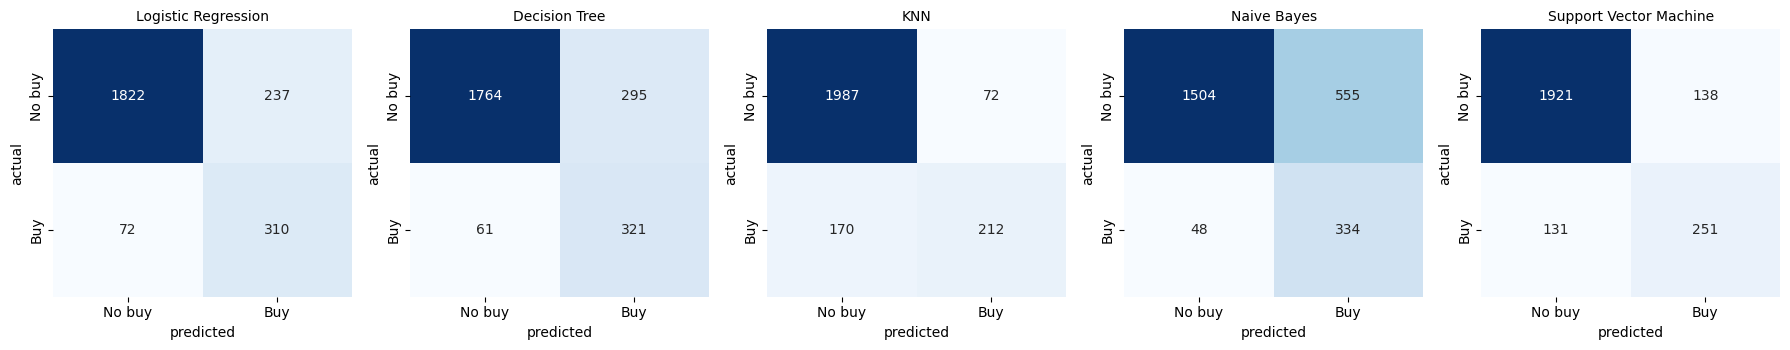

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, (name, m) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, (m.predict_proba(X_test)[:, 1] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No buy", "Buy"], yticklabels=["No buy", "Buy"])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
plt.tight_layout()
plt.show()

### Saving the models and the files the app needs

In [11]:
file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib",
}
import os
os.makedirs("model", exist_ok=True)
for name, m in models.items():
    joblib.dump(m, os.path.join("model", file_names[name]))

# the fitted preprocessing on its own, as a separate artifact
joblib.dump(models["Logistic Regression"].named_steps["prep"],
            "model/preprocessor.joblib")

results.round(4).to_csv("model/test_metrics.csv")

info = {
    "target": TARGET,
    "features": features,
    "positive_label": "True (purchase)",
    "seed": SEED,
    "models": file_names,
    "best_params": {n: {k.replace("clf__", ""): str(v)
                        for k, v in s.best_params_.items()} for n, s in best.items()},
    "versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__,
                 "numpy": np.__version__},
}
with open("model/model_info.json", "w") as f:
    json.dump(info, f, indent=2)

for f in sorted(os.listdir("model")):
    print(f"{f:28s} {os.path.getsize(os.path.join('model', f)) / 1024:8.1f} KB")

decision_tree.joblib             15.3 KB
knn.joblib                     5118.2 KB
logistic_regression.joblib        8.0 KB
model_info.json                   1.2 KB
naive_bayes.joblib                9.4 KB
preprocessor.joblib               6.8 KB
svm.joblib                     1888.7 KB
test_metrics.csv                  0.3 KB


The comparison table and my observations on each model are in `README.md`. The app loads the
saved files from `model/` and only predicts on whatever test CSV is uploaded.